In [10]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans

In [11]:

image_path = "C:/Users/moham/Downloads/testat/vini.png"
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

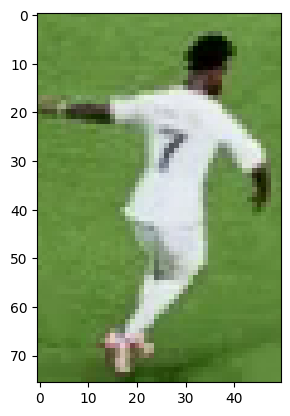

In [12]:
plt.imshow(image)
plt.show()

# take the top half of the image

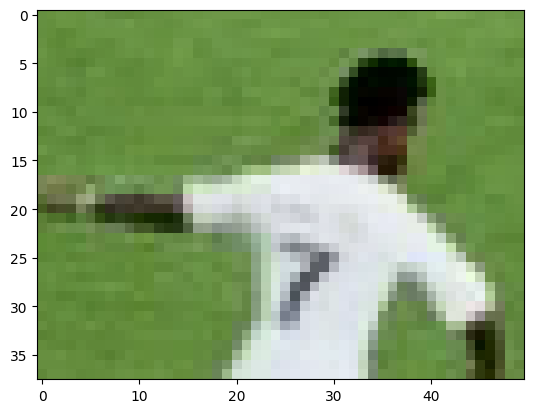

In [13]:
top_half_image=  image[0: int(image.shape[0]/2), :]
plt.imshow(top_half_image)
plt.show()

# Cluster the image into two clusters

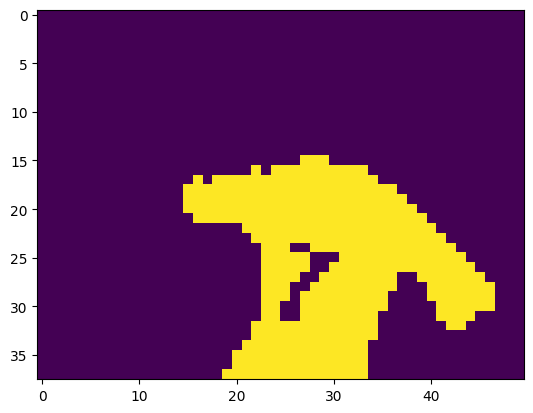

In [14]:
# Reshape the image into 2d array
image_2d = top_half_image.reshape(-1, 3)

# perform k-means clustering with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=0)
kmeans.fit(image_2d)

# get the cluster labels
labels = kmeans.labels_

# reshape the labels into the orginal image shape
clustered_image = labels.reshape(top_half_image.shape[0], top_half_image.shape[1])

# Display the clustered image
plt.imshow(clustered_image)
plt.show()

In [ ]:
corner_clusters = [clustered_image[0, 0], clustered_image[0, -1], clustered_image[-1, 0], clustered_image[-1, -1]]
non_player_cluster = max(set(corner_clusters), key=corner_clusters.count)
#print(non_player_cluster)

0


In [ ]:
player_cluster = 1-non_player_cluster
#print(player_cluster)

1


In [17]:
kmeans.cluster_centers_[player_cluster]

array([212.22193878, 220.9872449 , 217.14540816])

## Kmeanssss

In [6]:
from tqdm import tqdm
from ultralytics import YOLO
import supervision as sv
import torch
from transformers import AutoProcessor, SiglipVisionModel
import numpy as np
from more_itertools import chunked
import cv2
import umap
from sklearn.cluster import KMeans

In [5]:



SOURCE_VIDEO_PATH = "../input_videos/training_final.mp4"
PLAYER_ID = 4
STRIDE = 10
model = YOLO("../models/best_new.pt")

frame_generator = sv.get_video_frames_generator(
    source_path=SOURCE_VIDEO_PATH, stride=STRIDE)


crops = []
for frame in tqdm(frame_generator, desc='collecting crops'):
    result = model.predict(frame, conf=0.3)[0]
    detections = sv.Detections.from_ultralytics(result)
    detections = detections.with_nms(threshold=0.5, class_agnostic=True)
    detections = detections[detections.class_id == PLAYER_ID]
    # players_crops = [sv.crop_image(frame, xyxy) for xyxy in detections.xyxy]
    # crops += players_crops
    for xyxy in detections.xyxy:
        full_crop = sv.crop_image(frame, xyxy)
        height = full_crop.shape[0]
        top_half = full_crop[int(height*0.15):int(height*0.6)]  # keep top half
        crops.append(top_half)

collecting crops: 0it [00:00, ?it/s]


0: 384x640 8 players, 1 playername, 1043.9ms
Speed: 8.5ms preprocess, 1043.9ms inference, 17.8ms postprocess per image at shape (1, 3, 384, 640)


collecting crops: 1it [00:03,  3.11s/it]


0: 384x640 7 players, 1 playername, 1 referee, 915.5ms
Speed: 5.4ms preprocess, 915.5ms inference, 2.1ms postprocess per image at shape (1, 3, 384, 640)


collecting crops: 2it [00:04,  1.84s/it]

...

collecting crops: 186it [03:09,  1.12s/it]


0: 384x640 1 ball, 7 players, 872.9ms
Speed: 4.5ms preprocess, 872.9ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)


collecting crops: 187it [03:10,  1.06s/it]


0: 384x640 1 ball, 7 players, 904.1ms
Speed: 18.3ms preprocess, 904.1ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)


collecting crops: 188it [03:11,  1.02s/it]


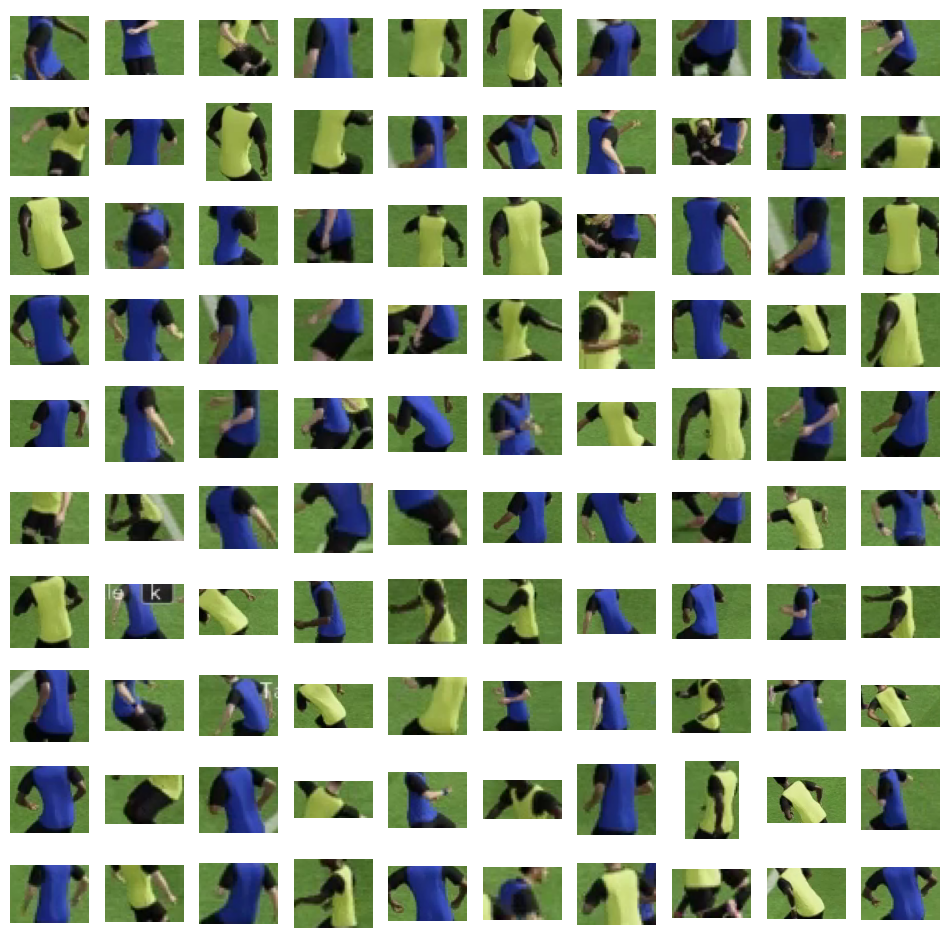

1399


In [11]:
sv.plot_images_grid(crops[:100], grid_size=(10, 10))
print(len(crops))

In [12]:


SIGLIP_MODEL_PATH = 'google/siglip-base-patch16-224'

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)
EMBEDDINGS_MODEL = SiglipVisionModel.from_pretrained(SIGLIP_MODEL_PATH).to(DEVICE)
EMBEDDINGS_PROCESSOR = AutoProcessor.from_pretrained(SIGLIP_MODEL_PATH)

cpu


In [13]:

BATCH_SIZE = 32

crop_pillow = [sv.cv2_to_pillow(crop) for crop in crops]
batches = chunked(crop_pillow, BATCH_SIZE)
data = []
with torch.no_grad():
    for batch in tqdm(batches, desc='embedding extraction'):
        inputs = EMBEDDINGS_PROCESSOR(images=batch, return_tensors="pt").to(DEVICE)
        outputs = EMBEDDINGS_MODEL(**inputs)
        embeddings = torch.mean(outputs.last_hidden_state, dim=1).cpu().numpy()
        data.append(embeddings)

data = np.concatenate(data)
initial_data = data

embedding extraction: 44it [05:37,  7.66s/it]


In [14]:

print(initial_data.shape)  # (470, 768)

REDUCER = umap.UMAP(n_components=3)
REDUCER.fit(initial_data)  # initial_data is shape (470, 768)

CLUSTERING_MODEL = KMeans(n_clusters=2)
initial_projection = REDUCER.transform(initial_data)
print(initial_projection.shape)  # (470, 3)
CLUSTERING_MODEL.fit(initial_projection)

(1399, 768)


(1399, 3)


KMeans(n_clusters=2)

In [15]:
import joblib

# Save KMeans model
joblib.dump(CLUSTERING_MODEL, "kmeans_trained_cpu.pkl")

# Save UMAP reducer (optional, if you also want to save the reducer)
# joblib.dump(projections, "projections_model.pkl")
joblib.dump(REDUCER, "reducer_model_cpu.pkl")

['reducer_model_cpu.pkl']

In [17]:
reducer = joblib.load("./reducer_model_cpu.pkl")
kmeans_trained = joblib.load("./kmeans_trained_cpu.pkl")

In [19]:
projections = reducer.transform(initial_data)
clusters = kmeans_trained.predict(projections)

[1 1 0 1 0 0 1 1 1 1]
838


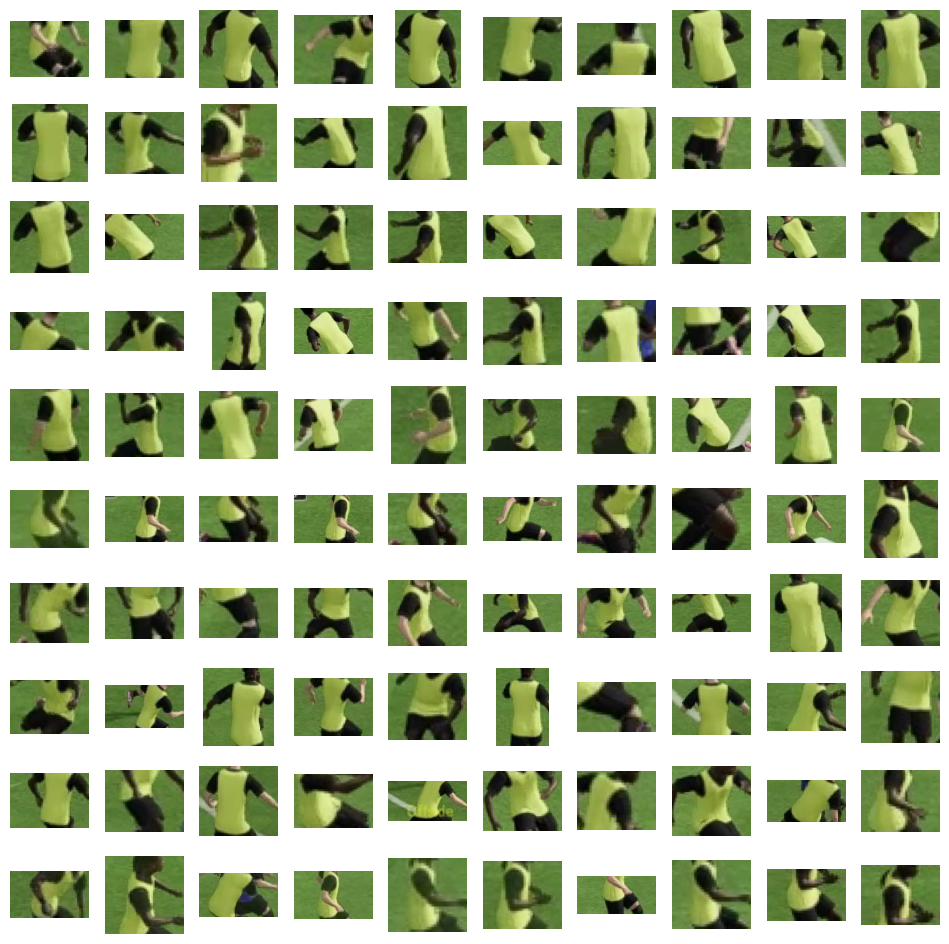

In [22]:
print(clusters[:10])
team_0 = [crop for crop, cluster in zip(crops, clusters) if cluster == 0]
team_1 = [crop for crop, cluster in zip(crops, clusters) if cluster == 1]
print(len(team_1))
sv.plot_images_grid(team_0[:100], grid_size=(10, 10))